In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os

In [23]:
RESULTS_DIR = "../results"

PATH_PRODUCT_SCORES = f"{RESULTS_DIR}/supplement/product_scores.csv"

PATH_RATER_PARAMETERS = f"{RESULTS_DIR}/main/rater_parameters.csv"

PATH_RAW_RATINGS = f"{RESULTS_DIR}/data/ratings_wide.csv"

PATH_ACTIONS = f"../data/raw/action_events_raw.csv"

PATH_VAEP_VALUES = f"../../../../00-data/vaep_values.csv"

df_product_scores = pd.read_csv(PATH_PRODUCT_SCORES)
df_rater_parameters = pd.read_csv(PATH_RATER_PARAMETERS)
df_raw_ratings = pd.read_csv(PATH_RAW_RATINGS)
df_actions = pd.read_csv(PATH_ACTIONS)
df_vaep_values = pd.read_csv(PATH_VAEP_VALUES)

In [24]:
df_raw_ratings.columns.str.startswith("R")

array([False,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True])

In [25]:
df_raw_ratings.columns[
    df_raw_ratings.columns.str.startswith("R")
]

Index(['R01', 'R02', 'R03', 'R04', 'R05', 'R06', 'R07', 'R08', 'R09', 'R10',
       'R11', 'R12', 'R13', 'R14', 'R15', 'R16', 'R17', 'R18', 'R19', 'R23',
       'R24', 'R25', 'R26', 'R27', 'R30'],
      dtype='str')

In [26]:
df_raw_ratings.loc[:, 'raw_mean'] = df_raw_ratings[
    df_raw_ratings.columns[df_raw_ratings.columns.str.startswith("R")]
].mean(axis=1)

df_raw_mean_ratings = df_raw_ratings[['product_id', 'raw_mean']]

In [28]:
df_actions_rated = pd.merge(df_actions, df_product_scores, how="right", left_on="id", right_on="product_id").drop(
    columns=["start_x_video", "end_x_video", "start_y_video", "end_y_video", "product_id"]
    )

df_actions_rated = pd.merge(df_actions_rated, df_vaep_values[['original_event_id', 'vaep_value', 'offensive_value', 'defensive_value']], how="left", left_on="id", right_on="original_event_id")

df_actions_rated = pd.merge(df_actions_rated, df_raw_mean_ratings, how="left", left_on="id", right_on="product_id").drop(columns=["product_id"])

<Axes: >

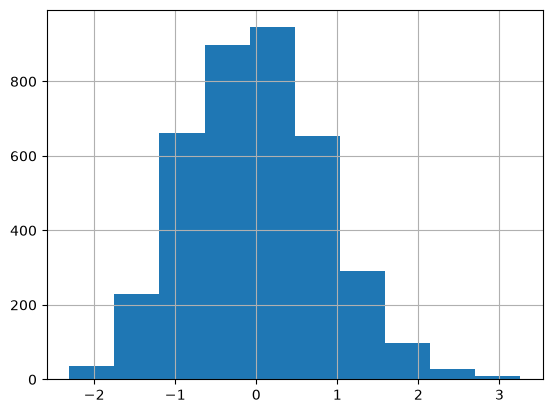

In [29]:
df_actions_rated['theta_eap'].hist()

<Axes: >

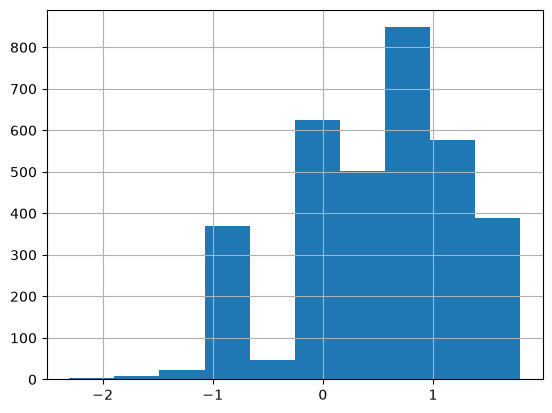

In [30]:
np.log(df_actions_rated[df_actions_rated['raw_mean'] > 0]['raw_mean']).hist()

## Identify similar actions rated by raters with very different tendencies

<Axes: xlabel='theta_eap', ylabel='raw_mean'>

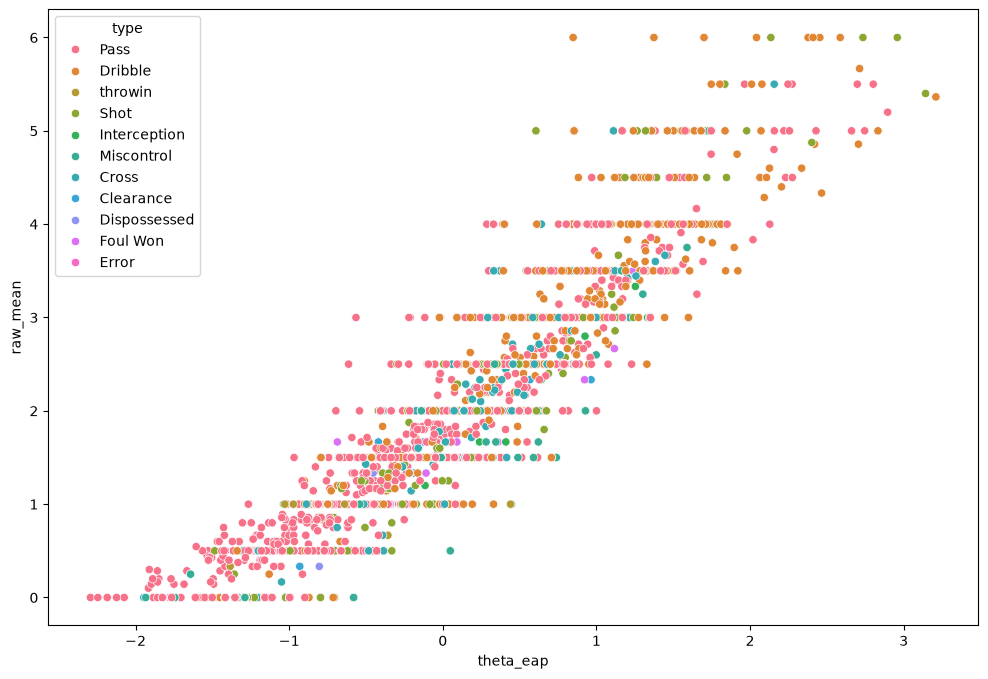

In [29]:
fig, ax = plt.subplots(figsize=(12, 8))
sns.scatterplot(data=df_actions_rated, x="theta_eap", y="raw_mean", hue="type", ax=ax)

In [34]:
df_candidates

,id,match_id,period,minute,second,timestamp,possession,possession_team,duration,team,...,rel_post,info_at_eap,rel_info,n_ratings,raters,original_event_id,vaep_value,offensive_value,defensive_value,raw_mean
25,012abd99-d8ad-4044-976f-42af0d62852c,3920388,2,64,51,00:19:51.789,121,Gambia,1.189593,Gambia,...,0.892461,7.631506,0.884145,6,R07;R09;R11;R16;R23;R25,012abd99-d8ad-4044-976f-42af0d62852c,0.028036,0.028324,-0.000288,3.666667
44,01d69b71-671a-4671-ab60-8bdbb2607555,3857293,1,3,29,00:03:29.968,8,Ghana,1.255852,Uruguay,...,0.938811,14.551027,0.935696,9,R01;R03;R05;R06;R13;R16;R23;R25;R27,01d69b71-671a-4671-ab60-8bdbb2607555,0.023848,0.023675,0.000173,2.888889
53,025cf792-1a11-4df3-ad9d-774bd03a63b4,3942382,2,87,28,00:42:28.070,114,Turkey,1.541608,Turkey,...,0.667327,1.975483,0.663920,2,R01;R03,025cf792-1a11-4df3-ad9d-774bd03a63b4,-0.003252,-0.003396,0.000143,3.000000
58,0289e247-bc20-46e6-8206-bd14c58e50d5,3835324,1,33,23,00:33:23.844,73,Sweden Women's,0.988774,Sweden Women's,...,0.552837,1.631204,0.619946,2,R08;R09,0289e247-bc20-46e6-8206-bd14c58e50d5,0.001215,0.001132,0.000083,4.500000
73,03062a41-b6ab-454d-a2f3-c162beb5d962,3902967,2,64,28,00:19:28.481,127,England Women's,0.984423,England Women's,...,0.908050,8.428788,0.893942,7,R03;R05;R06;R11;R13;R18;R23,03062a41-b6ab-454d-a2f3-c162beb5d962,-0.010372,-0.010657,0.000285,3.571429
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3750,f865aff9-3b52-4b5a-ba4f-2244c16f5652,3857279,1,44,37,00:44:37.385,61,France,0.853147,France,...,0.658429,2.351392,0.701617,1,R02,f865aff9-3b52-4b5a-ba4f-2244c16f5652,0.268137,0.267688,0.000449,5.000000
3757,f909e61a-ac0d-46b9-bd9b-84fc3e19ed96,3943076,1,18,3,00:18:03.341,38,Canada,4.811511,Canada,...,0.666437,2.483704,0.712949,2,R01;R10,f909e61a-ac0d-46b9-bd9b-84fc3e19ed96,-0.003885,-0.004224,0.000339,3.500000
3778,fa9c3afc-9655-4fc2-9a9c-f0d9d693e8e3,3943076,2,88,54,00:43:54.889,182,Uruguay,0.894753,Uruguay,...,0.901356,9.812215,0.907512,7,R01;R07;R11;R12;R16;R23;R24,fa9c3afc-9655-4fc2-9a9c-f0d9d693e8e3,0.009716,0.009558,0.000158,4.000000
3792,fbd2cd72-5831-40b0-ba0a-4d4de7177818,3922237,2,80,17,00:35:17.571,148,Namibia,2.994017,Namibia,...,0.667327,1.975483,0.663920,2,R01;R03,fbd2cd72-5831-40b0-ba0a-4d4de7177818,0.018305,0.017143,0.001162,3.000000


In [67]:
df_candidates = df_actions_rated[(df_actions_rated['type'] == 'Pass') & (
    df_actions_rated['theta_eap'] > 1) & (
        df_actions_rated['n_ratings'] == 2
    )].copy()

df_candidates = df_candidates[(df_candidates['theta_eap'] > 1) & (df_candidates['theta_eap'] < 1.5) & (
    (df_candidates['raw_mean'] == 2.5) | (df_candidates['raw_mean'] > 4.0)
    )]    
    


<Axes: xlabel='theta_eap', ylabel='raw_mean'>

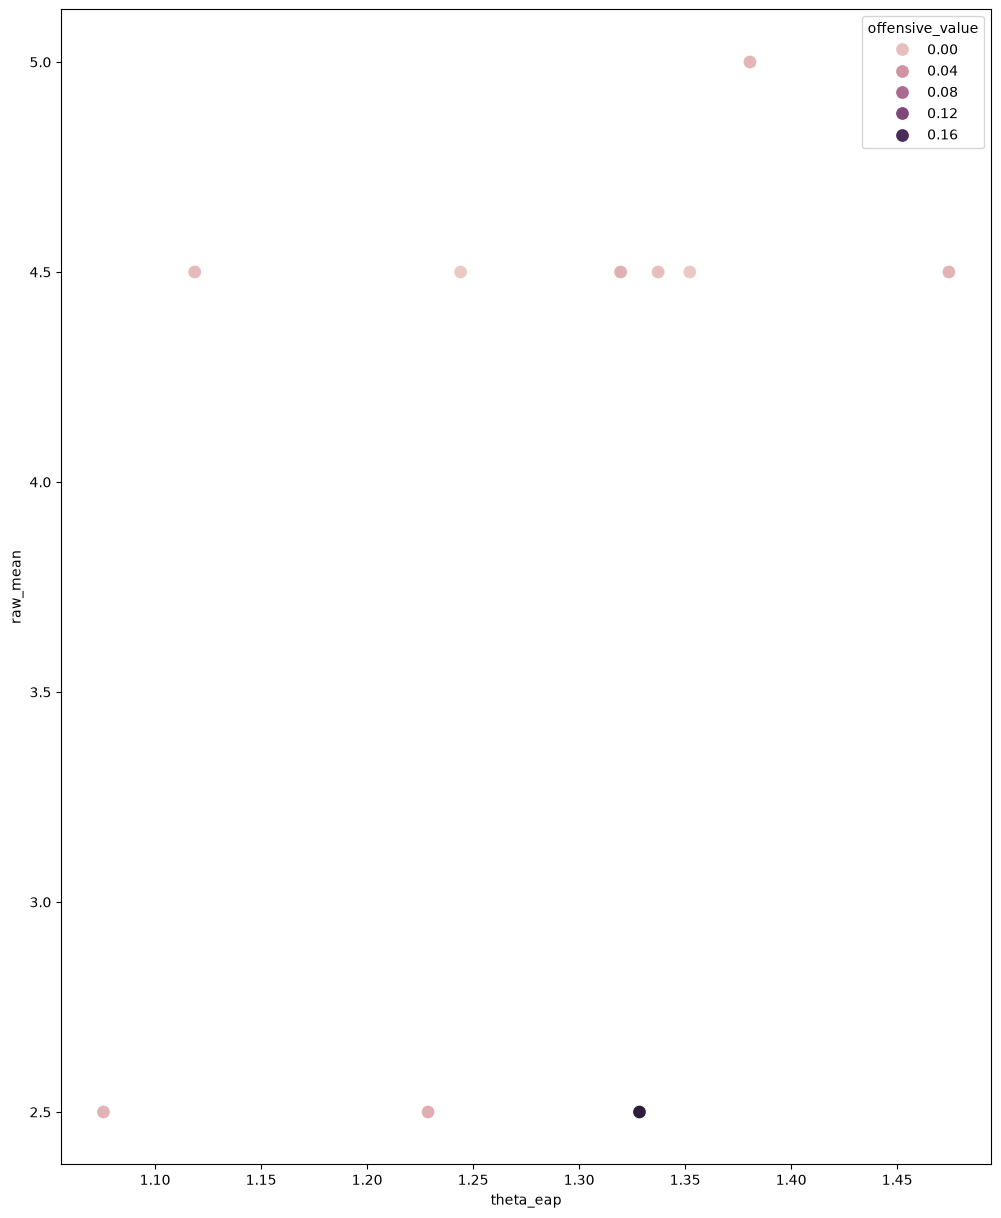

In [68]:
fig, ax = plt.subplots(figsize=(12, 15))
sns.scatterplot(data=df_candidates, x="theta_eap", y="raw_mean", hue="offensive_value", s=100, ax=ax)
# add text that shows when hovering over a point, the text shows the id of the action


In [71]:
df_candidates[['id', 'match_id', 'theta_eap', 'raw_mean', 'player', 'team']].sort_values(by='raw_mean', ascending=False).head(20)

,id,match_id,theta_eap,raw_mean,player,team
1111,3e004a7a-306d-4909-9643-17cc09ac4fd6,3869420,1.380570,5.0,Neymar da Silva Santos Junior,Brazil
58,0289e247-bc20-46e6-8206-bd14c58e50d5,3835324,1.337251,4.5,Hanna Erica Maria Glas,Sweden Women's
180,09455f33-5a64-4b61-b162-d488e264b118,3857295,1.118709,4.5,Francisco Javier Calvo Quesada,Costa Rica
1728,66d421cc-e278-44f7-8576-9b215e8775de,3835336,1.319564,4.5,Verena Hanshaw,Austria Women's
3630,ef587ec0-3498-49d4-a6be-a2d9416086e7,3942349,1.474394,4.5,Bruno Miguel Borges Fernandes,Portugal
2347,8fe87892-a7e7-4a2e-a404-049df5cc4b5a,3835336,1.244070,4.5,Caroline Graham Hansen,Norway Women's
1902,71c7d2b5-f666-42ba-9f9a-358e7d3c9e4f,3939980,1.319564,4.5,Bobby Armani De Cordova-Reid,Jamaica
3640,f035ecaa-e298-4288-8c00-4d419ca6fefa,3942382,1.352212,4.5,Tijjani Reijnders,Netherlands
3323,d7629f73-68ae-40a6-98d0-ca6ac2003513,3869420,1.244070,4.5,Raphael Dias Belloli,Brazil
1515,57cdbf39-140d-4cb9-af01-3cd28bbb5da8,3922243,1.328462,2.5,Abdessamad Ezzalzouli,Morocco


***


In [74]:
PLAYER_MIN_ACTIONS = 10

df_players = df_actions_rated.groupby('player').agg(
    team=('team', 'first'),
    n_actions=('id', 'count'),
    n_rated_actions=('rel_post', lambda x: x.notnull().sum()),
    n_unrated_actions=('rel_post', lambda x: x.isnull().sum()),
    mean_rel_post=('rel_post', 'mean'),
    mean_theta_eap=('theta_eap', 'mean'),
    mean_n_ratings=('n_ratings', 'mean'),
    sum_theta_eap=('theta_eap', 'sum'),
    sum_vaep_value=('vaep_value', 'sum'),
    sum_offensive_value=('offensive_value', 'sum'),
    sum_defensive_value=('defensive_value', 'sum')
).reset_index().sort_values(by='mean_theta_eap', ascending=False).copy()

df_players[df_players['n_actions'] > PLAYER_MIN_ACTIONS].sort_values(by='sum_theta_eap', ascending=False).head(20).round(2)

,player,team,n_actions,n_rated_actions,n_unrated_actions,mean_rel_post,mean_theta_eap,mean_n_ratings,sum_theta_eap,sum_vaep_value,sum_offensive_value,sum_defensive_value
170,Caroline Graham Hansen,Norway Women's,11,11,0,0.75,0.69,2.82,7.58,-0.05,-0.04,-0.00
803,Mohammed Kudus,Ghana,14,14,0,0.71,0.43,2.43,5.96,-0.00,0.00,-0.01
622,Kosovare Asllani,Sweden Women's,12,12,0,0.65,0.41,2.50,4.96,-0.02,-0.00,-0.01
375,Georgia Stanway,England Women's,12,12,0,0.70,0.34,1.75,4.04,0.03,0.05,-0.02
562,Julio César Enciso Espínola,Paraguay,12,12,0,0.64,0.27,1.92,3.30,-0.07,-0.06,-0.02
254,Deon Hotto Kavendji,Namibia,11,11,0,0.75,0.27,3.36,2.95,0.06,0.06,0.00
1190,Ángel Fabián Di María Hernández,Argentina,11,11,0,0.68,0.26,2.55,2.84,-0.01,-0.00,-0.01
651,Lia Wälti,Switzerland Women's,12,12,0,0.77,0.19,2.42,2.31,-0.00,-0.00,-0.00
767,Mayra Tatiana Ramírez Ramírez,Colombia Women's,12,12,0,0.69,0.19,1.92,2.22,-0.07,-0.06,-0.01
629,Kyra Lillee Cooney-Cross,Australia Women's,11,11,0,0.67,0.15,2.45,1.61,0.08,0.08,-0.01


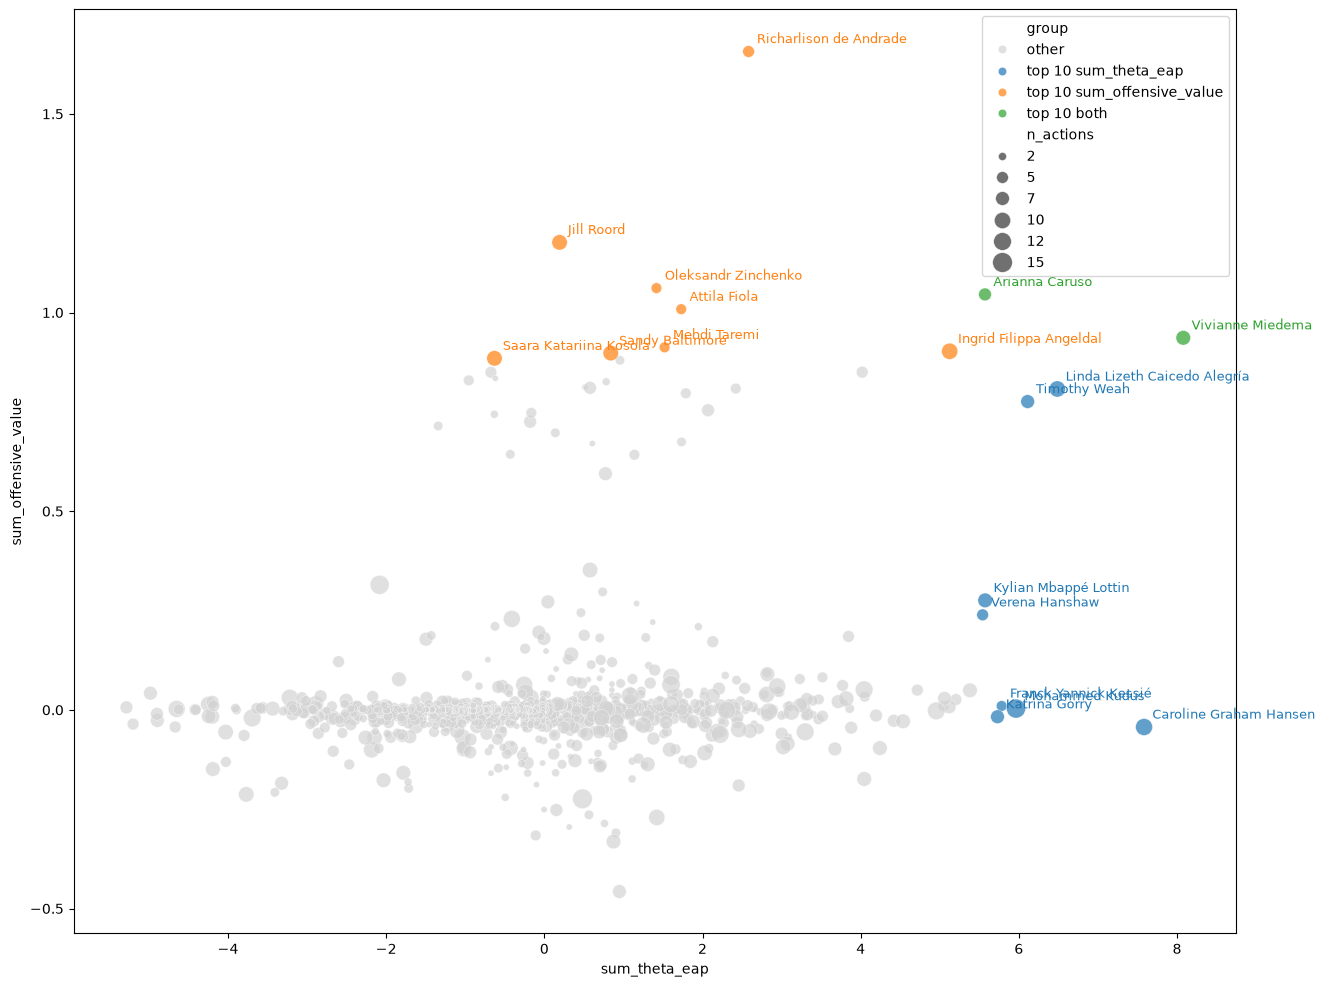

In [86]:
TOP_N = 10

top_theta = set(df_players.nlargest(TOP_N, "sum_theta_eap")["player"])
top_off = set(df_players.nlargest(TOP_N, "sum_offensive_value")["player"])

def _group(player):
    if player in top_theta and player in top_off:
        return f"top {TOP_N} both"
    if player in top_theta:
        return f"top {TOP_N} sum_theta_eap"
    if player in top_off:
        return f"top {TOP_N} sum_offensive_value"
    return "other"

df_plot = df_players.copy()
df_plot["group"] = df_plot["player"].map(_group)

palette = {
    "other": "lightgrey",
    f"top {TOP_N} sum_theta_eap": "tab:blue",
    f"top {TOP_N} sum_offensive_value": "tab:orange",
    f"top {TOP_N} both": "tab:green",
}

fig, ax = plt.subplots(figsize=(15, 12))
sns.scatterplot(
    data=df_plot, x="sum_theta_eap", y="sum_offensive_value",
    hue="group", palette=palette, hue_order=list(palette),
    size="n_actions", sizes=(20, 200), alpha=0.7, ax=ax,
)

for _, row in df_plot[df_plot["group"] != "other"].iterrows():
    ax.annotate(
        row["player"], (row["sum_theta_eap"], row["sum_offensive_value"]),
        xytext=(6, 6), textcoords="offset points", fontsize=9,
        color=palette[row["group"]],
    )


In [73]:
TEAM_MIN_ACTIONS = 50

df_teams = df_actions_rated.groupby('team').agg(
    n_actions=('id', 'count'),
    n_rated_actions=('rel_post', lambda x: x.notnull().sum()),
    n_unrated_actions=('rel_post', lambda x: x.isnull().sum()),
    mean_rel_post=('rel_post', 'mean'),
    mean_theta_eap=('theta_eap', 'mean'),
    mean_n_ratings=('n_ratings', 'mean'),
    sum_theta_eap=('theta_eap', 'sum'),
    sum_vaep_value=('vaep_value', 'sum'),
    sum_offensive_value=('offensive_value', 'sum'),
    sum_defensive_value=('defensive_value', 'sum')
).reset_index().sort_values(by='sum_theta_eap', ascending=False).copy()

df_teams[df_teams['n_actions'] > TEAM_MIN_ACTIONS].sort_values(by='sum_theta_eap', ascending=False).head(20).round(3)

,team,n_actions,n_rated_actions,n_unrated_actions,mean_rel_post,mean_theta_eap,mean_n_ratings,sum_theta_eap,sum_vaep_value,sum_offensive_value,sum_defensive_value
13,Canada,70,70,0,0.682,0.270,2.371,18.927,-0.006,0.025,-0.030
43,Italy Women's,51,51,0,0.692,0.184,2.431,9.364,0.868,0.881,-0.012
61,Paraguay,65,65,0,0.665,0.134,2.292,8.692,-0.417,-0.386,-0.031
50,Morocco,64,64,0,0.673,0.134,2.438,8.554,-0.243,-0.212,-0.031
17,Colombia Women's,61,61,0,0.706,0.100,2.705,6.106,0.652,0.696,-0.044
77,Sweden Women's,75,75,0,0.727,0.077,2.893,5.751,1.083,1.131,-0.049
53,Namibia,57,57,0,0.735,0.093,2.895,5.288,0.010,0.005,0.004
4,Australia Women's,70,70,0,0.702,0.075,2.614,5.277,-0.292,-0.107,-0.185
27,England,67,67,0,0.714,0.076,2.597,5.062,0.507,0.591,-0.084
35,Germany Women's,72,72,0,0.720,0.066,2.667,4.724,-0.255,-0.210,-0.044


/tmp/ipykernel_564711/1195959971.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right");


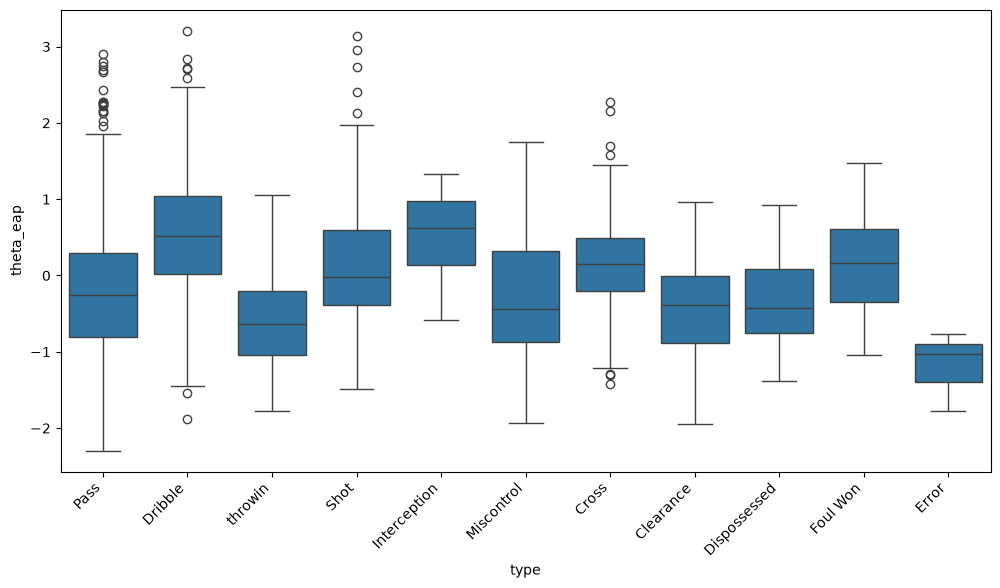

In [34]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=df_actions_rated, x="type", y="theta_eap")
# rotate x axis ticks
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right");

<Axes: >

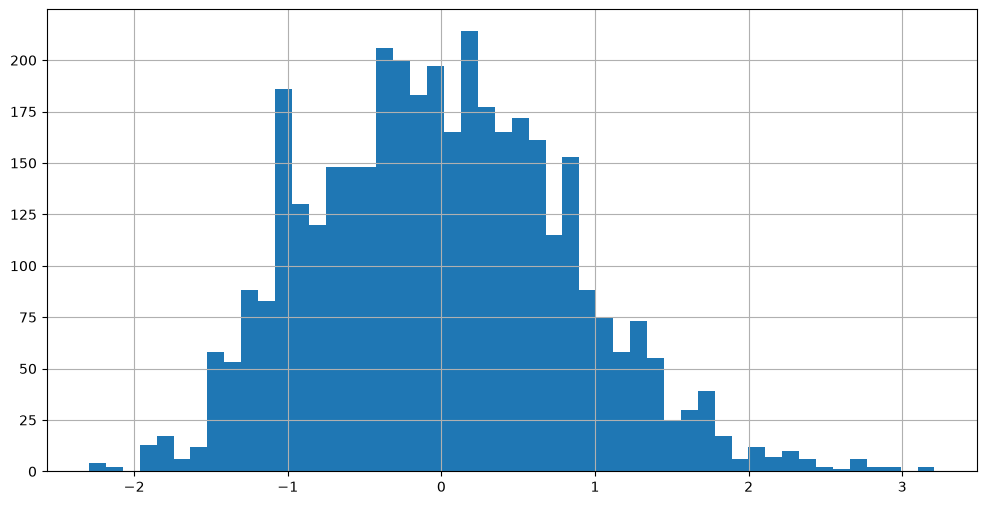

In [40]:
df_actions_rated.theta_eap.hist(bins=50, figsize=(12, 6))


In [63]:
df_actions_rated[['theta_eap', 'vaep_value', 'offensive_value', 'defensive_value']].corr().round(2)

,theta_eap,vaep_value,offensive_value,defensive_value
theta_eap,1.00,0.11,0.11,0.04
vaep_value,0.11,1.00,1.00,0.07
offensive_value,0.11,1.00,1.00,0.03
defensive_value,0.04,0.07,0.03,1.00


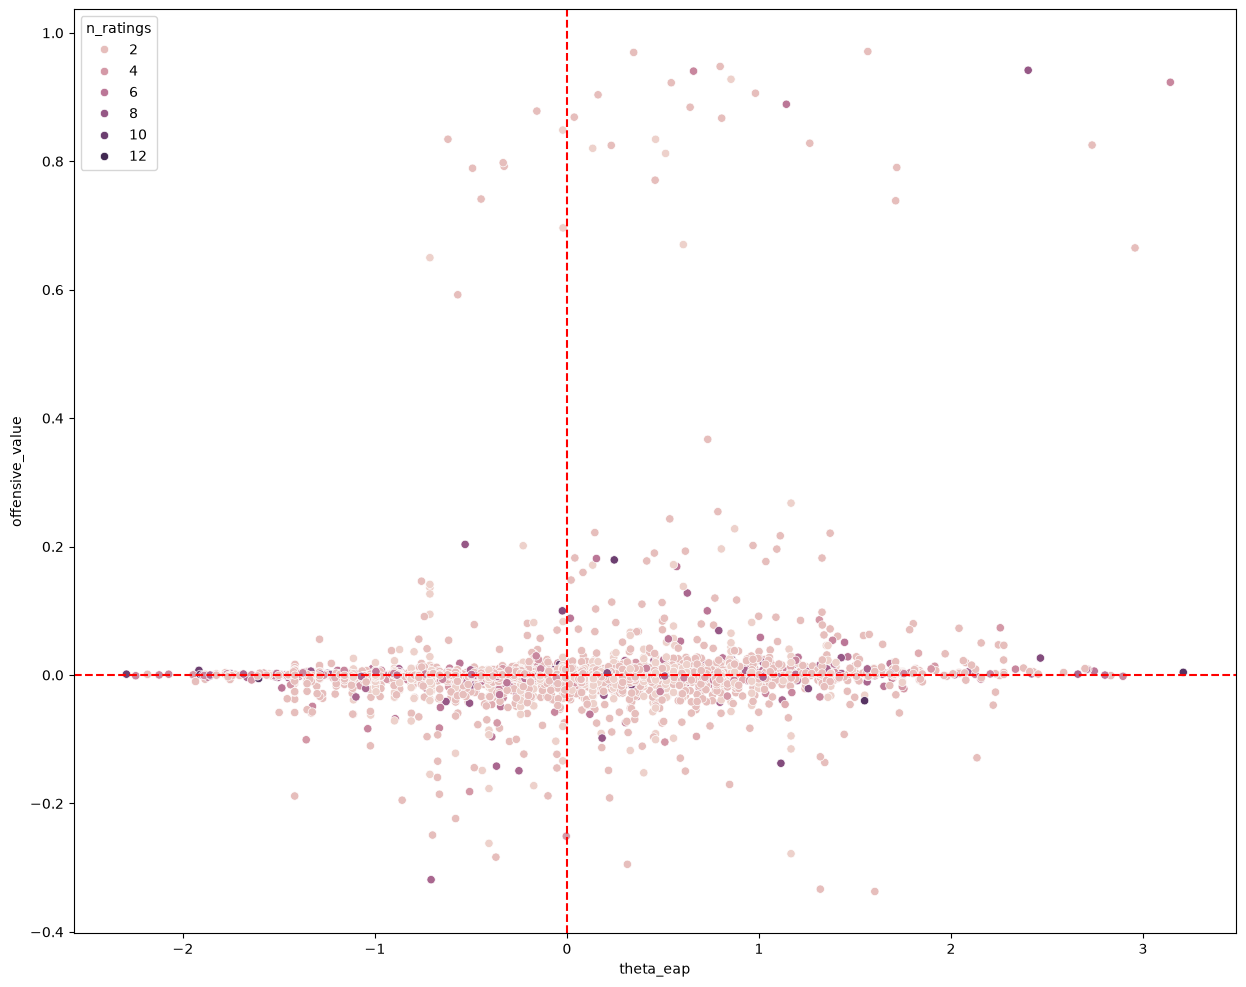

In [72]:
#df_plot = df_actions_rated[df_actions_rated['offensive_value'] < 0.6].copy()
fig, ax = plt.subplots(figsize=(15, 12))
sns.scatterplot(data=df_actions_rated, x="theta_eap", y="offensive_value", hue="n_ratings")
ax.axhline(0, color='red', linestyle='--')
ax.axvline(0, color='red', linestyle='--')

<Axes: xlabel='theta_eap', ylabel='rel_post'>

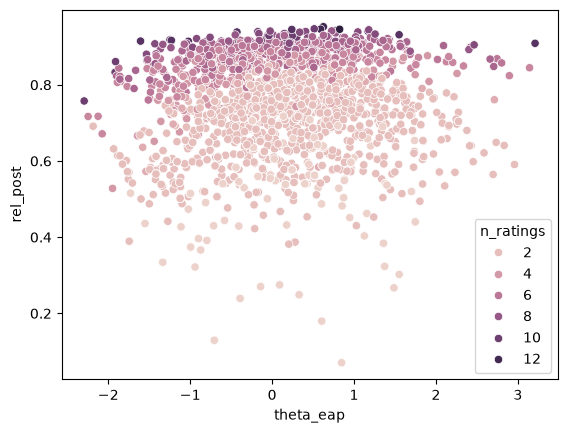

In [4]:
sns.scatterplot(data=df_product_scores, x="theta_eap", y="rel_post", hue="n_ratings")